# CIE Lab color histograms: detection demo

How the color pipeline works in **CIE Lab** on the **NYC street-level images**, step by step on two example images, then the
results on all NYC images. The NYC annotations are not used: this is a qualitative check of what the detector tuned on the HF data finds.

1. Templates: CIE Lab histograms of the Vistas reference crops
2. Preprocessing: NLM denoising and conversion to CIE Lab
3. Multi-scale sliding windows (+ orange prescreen for cones)
4. Similarity: D3 distance from each window to its nearest template
5. Detection: NMS + the distance threshold tuned on HF validation
6. Results on all NYC images (qualitative)

CIE Lab separates lightness L from two color axes: a (green → red) and b (blue → yellow). Orange is high a and high b. 8 L bins + 16 a + 16 b = 40 values.

Needs `python scripts/build_reference.py` (plus `python scripts/run_detection.py --split validation` and
`python scripts/validate_features.py` for the thresholds), `python scripts/run_detection.py --split nyc` to have been run first.

In [1]:
import json
import sys
from pathlib import Path

# The notebooks live in color_exp_demos/; the code and results are one level up
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from common.dataset import DATASET_DIR, NYC_ASPECTS, NYC_DIR, NYC_STRIDE_FRACTION, NYC_WIDTHS, SPLIT_FILE, load_dataset, map_labels, nyc_images
from common.preprocessing import denoise, orange_mask
from common.sliding_window import multiscale_windows, prescreen, size_range, window_histograms, window_sizes
from detection.postprocessing import box_iou, nms
from detection.template_matching import TEMPLATE_DIR, d3, load_reference, load_templates, nearest_template_distance
from evaluation.metrics import ground_truth_boxes, match
from features.color import SPACES

SPACE = "lab"
SP = SPACES[SPACE]
CHANNELS = {"rgb": ["R", "G", "B"], "hsv": ["H", "S", "V"], "lab": ["L", "a", "b"]}
SPACE_NAMES = {"rgb": "RGB", "hsv": "HSV", "lab": "Lab"}
RESULTS = ROOT / "results"

# Colors: one per color space (same in all three notebooks), one per class, and box styles for detections
SPACE_COLORS = {"rgb": "#2a78d6", "hsv": "#eb6834", "lab": "#1baf7a"}
CLASS_COLORS = {"cone": "#6250d6", "sign": "#e87ba4"}
BOX_STYLES = {"correct": dict(color="#008300", lw=2.5, ls="-"),
              "false": dict(color="#e34948", lw=1.2, ls="-"),
              "missed": dict(color="#eda100", lw=2, ls="--")}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
                     "axes.titlesize": 11, "axes.labelsize": 10, "figure.dpi": 80})

N_IMAGES = len(nyc_images())
IMAGE_DIR = NYC_DIR
# No boxes to measure on NYC: same multi-scale rule over a fixed width range
SIZES = {cls: size_range(*NYC_WIDTHS[cls], aspect) for cls, aspect in NYC_ASPECTS.items()}
STRIDE_FRACTION = NYC_STRIDE_FRACTION
reference = load_reference()[SPACE]
thresholds = json.loads((RESULTS / "thresholds.json").read_text())[SPACE]


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def plot_hist(ax, series, title):
    """Step plot of one or more histograms of this space; dotted lines separate the channels."""
    edges = np.cumsum(SP["bins"])
    for label, (hist, color) in series.items():
        ax.step(np.arange(len(hist)), hist, where="mid", color=color, lw=2, label=label)
    for edge in edges[:-1]:
        ax.axvline(edge - 0.5, color="#8a8984", ls=":", lw=0.8)
    ax.set_xticks(edges - np.array(SP["bins"]) / 2 - 0.5, CHANNELS[SPACE])
    ax.set_ylabel("fraction of pixels")
    ax.set_title(title)
    if len(series) > 1:
        ax.legend(fontsize=9, frameon=False)


def draw_boxes(ax, boxes, **style):
    for x0, y0, x1, y1 in boxes:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, **style))

## 1. Templates

The reference set is the Vistas crops with `role == "template"`: whole crops (no mask, to match unmasked windows),
denoised, histogrammed in CIE Lab. Loaded from `data/reference.npz`.

{'cone': 243, 'sign': 47} templates; histogram length 40


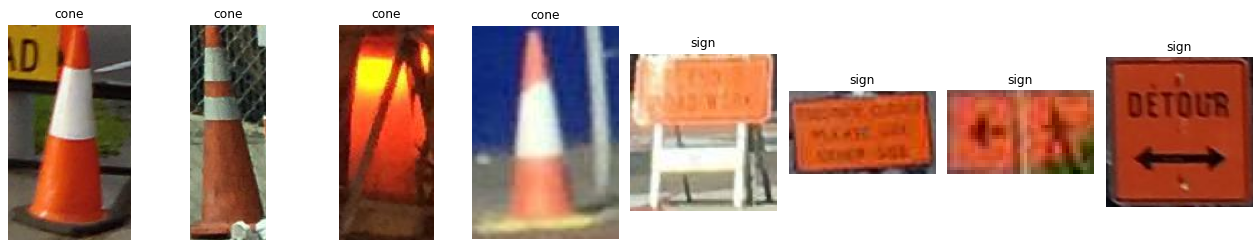

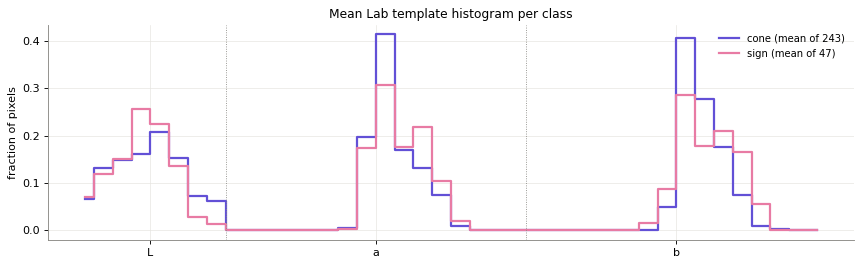

In [2]:
templates = load_templates()
print({cls: len(h) for cls, h in reference.items()}, "templates; histogram length", reference["cone"].shape[1])

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 8, figsize=(16, 3.2))
for ax, (_, row) in zip(axes, pd.concat([g.sample(4, random_state=0) for _, g in templates.groupby("class")]).iterrows()):
    ax.imshow(rgb(cv2.imread(str(TEMPLATE_DIR / row["crop"]))))
    ax.set_title(row["class"])
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 3.5))
plot_hist(ax, {f"{cls} (mean of {len(h)})": (h.mean(axis=0), CLASS_COLORS[cls]) for cls, h in reference.items()},
          f"Mean {SPACE_NAMES[SPACE]} template histogram per class")
plt.show()

## 2. Example images: denoising and color conversion

Two NYC images picked by eye: one with traffic cones, one with a construction sign.

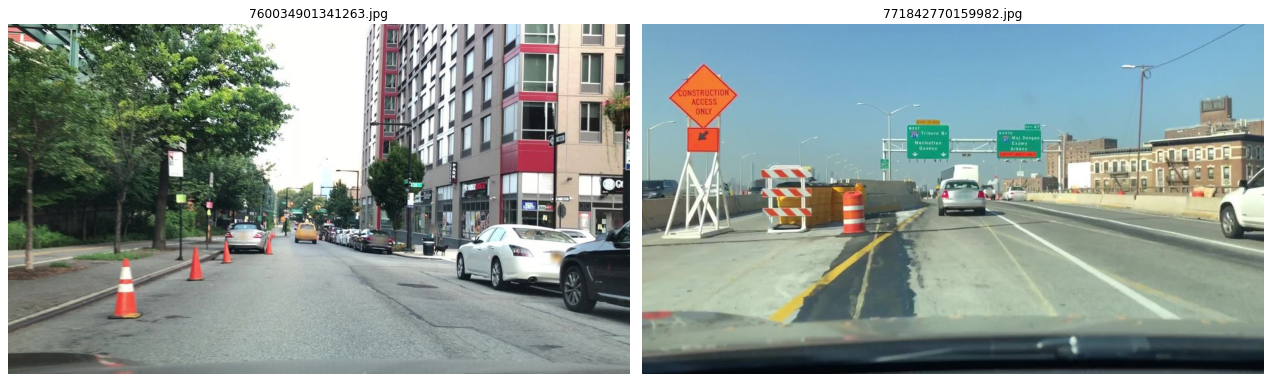

In [3]:
EXAMPLES = ["images/760034901341263.jpg", "images/771842770159982.jpg"]
originals = {p: cv2.imread(str(IMAGE_DIR / p)) for p in EXAMPLES}
images = {p: denoise(img) for p, img in originals.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, p in zip(axes, EXAMPLES):
    ax.imshow(rgb(originals[p]))
    ax.set_title(p.split("/")[-1])
    ax.axis("off")
plt.tight_layout()
plt.show()

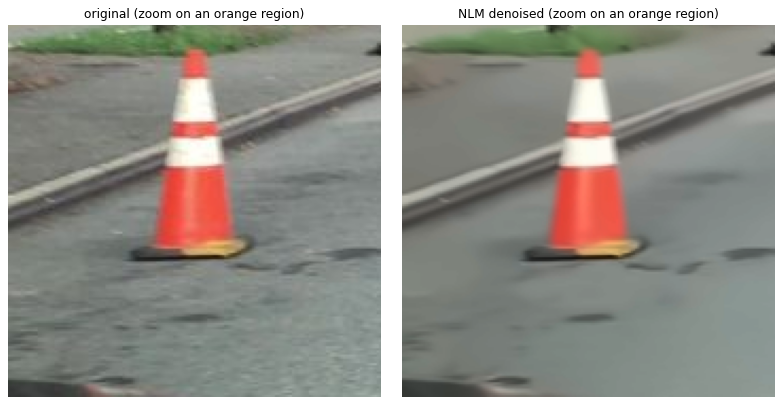

mean absolute change per pixel: 2.97


In [4]:
# Denoising, zoomed on the largest orange region of the first example
_, _, stats, _ = cv2.connectedComponentsWithStats(orange_mask(originals[EXAMPLES[0]]).astype(np.uint8))
x, y, w, h = stats[1:][stats[1:, cv2.CC_STAT_AREA].argmax(), :4]
cx, cy, half = x + w // 2, y + h // 2, max(w, h) * 2
zoom = np.s_[max(0, cy - half):cy + half, max(0, cx - half):cx + half]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [originals[EXAMPLES[0]], images[EXAMPLES[0]]], ["original", "NLM denoised"]):
    ax.imshow(rgb(img[zoom]))
    ax.set_title(f"{title} (zoom on an orange region)")
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"mean absolute change per pixel: {np.abs(originals[EXAMPLES[0]].astype(int) - images[EXAMPLES[0]]).mean():.2f}")

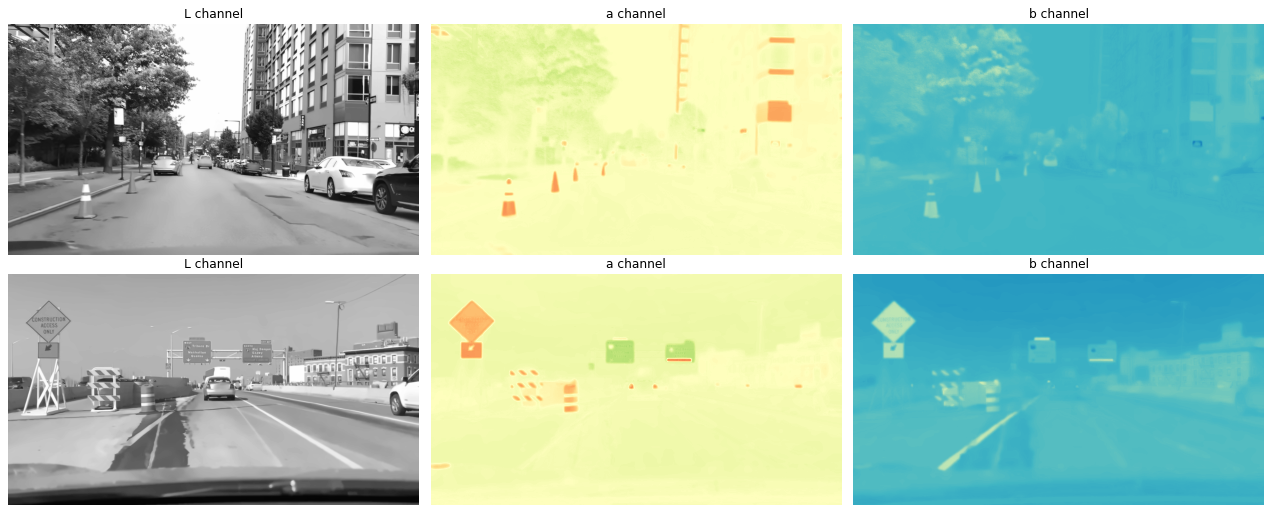

In [5]:
# The CIE Lab channels of both examples
converted = {p: SP["convert"](img) for p, img in images.items()}
cmaps = {"rgb": ["Reds", "Greens", "Blues"], "hsv": ["hsv", "gray", "gray"], "lab": ["gray", "RdYlGn_r", "YlGnBu_r"]}[SPACE]
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for row, p in zip(axes, EXAMPLES):
    for c, ax in enumerate(row):
        ax.imshow(converted[p][..., c], cmap=cmaps[c], vmin=0, vmax=SP["channel_max"][c] - 1)
        ax.set_title(f"{CHANNELS[SPACE][c]} channel")
        ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Multi-scale sliding windows

Window sizes come from a fixed range per class, since there are no NYC boxes to measure: widths grow ×1.25 per scale until they reach a quarter of the 1024 px image width (256 px). Sign windows start at 48 px, because smaller all-orange patches (traffic lights, buses, bike frames) beat whole objects in NMS; cone windows start at 16 px, since most NYC cones are narrower than 48 px. Cone windows are twice as tall as wide, sign windows square. Windows slide by a quarter of their width (half on HF). Cone windows are then prescreened: only windows with
≥ 2% orange pixels are kept. Sign windows are not prescreened (same as on the HF data).

cone: 14 scales (w x h): [(16, 32), (20, 40), (25, 50), (31, 62), (39, 78), (49, 98), (61, 122), (76, 153), (95, 191), (119, 238), (149, 298), (186, 373), (233, 466), (291, 582)]
sign: 9 scales (w x h): [(48, 48), (60, 60), (75, 75), (94, 94), (117, 117), (146, 146), (183, 183), (229, 229), (286, 286)]

760034901341263.jpg: 93,312 cone windows -> 3,209 after the orange prescreen (3.4%); 9,710 sign windows


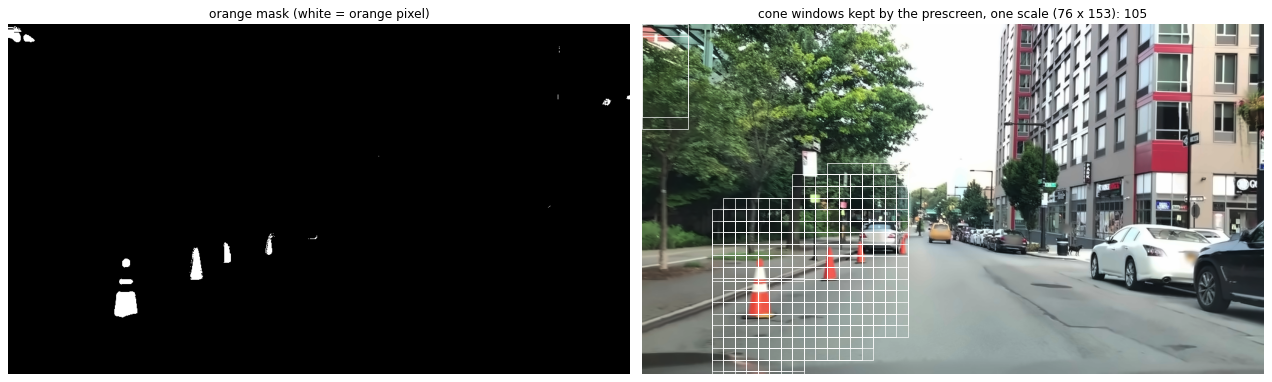

In [6]:
for cls, sizes in SIZES.items():
    print(f"{cls}: {len(sizes)} scales (w x h): {sizes}")

p = EXAMPLES[0]
mask = orange_mask(images[p])
all_cone = multiscale_windows(images[p].shape, SIZES["cone"], STRIDE_FRACTION)
kept_cone = prescreen(mask, all_cone)
print(f"\n{p.split('/')[-1]}: {len(all_cone):,} cone windows -> {len(kept_cone):,} after the orange prescreen "
      f"({len(kept_cone) / len(all_cone):.1%}); {len(multiscale_windows(images[p].shape, SIZES['sign'], STRIDE_FRACTION)):,} sign windows")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].imshow(mask, cmap="gray")
axes[0].set_title("orange mask (white = orange pixel)")
axes[1].imshow(rgb(images[p]))
mid = SIZES["cone"][len(SIZES["cone"]) // 2]
at_mid = kept_cone[(kept_cone[:, 2] - kept_cone[:, 0] == mid[0]) & (kept_cone[:, 3] - kept_cone[:, 1] == mid[1])]
draw_boxes(axes[1], at_mid, color="white", lw=0.6)
axes[1].set_title(f"cone windows kept by the prescreen, one scale ({mid[0]} x {mid[1]}): {len(at_mid)}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Similarity: D3 distance to the nearest template

Each window's CIE Lab histogram is compared with every template of its class using the slides' D3 distance,
$D_3(a, b) = \sum_i (h_i(a) - h_i(b))^2 / \max(h_i(a), h_i(b))$, and keeps the smallest (lower = more similar).

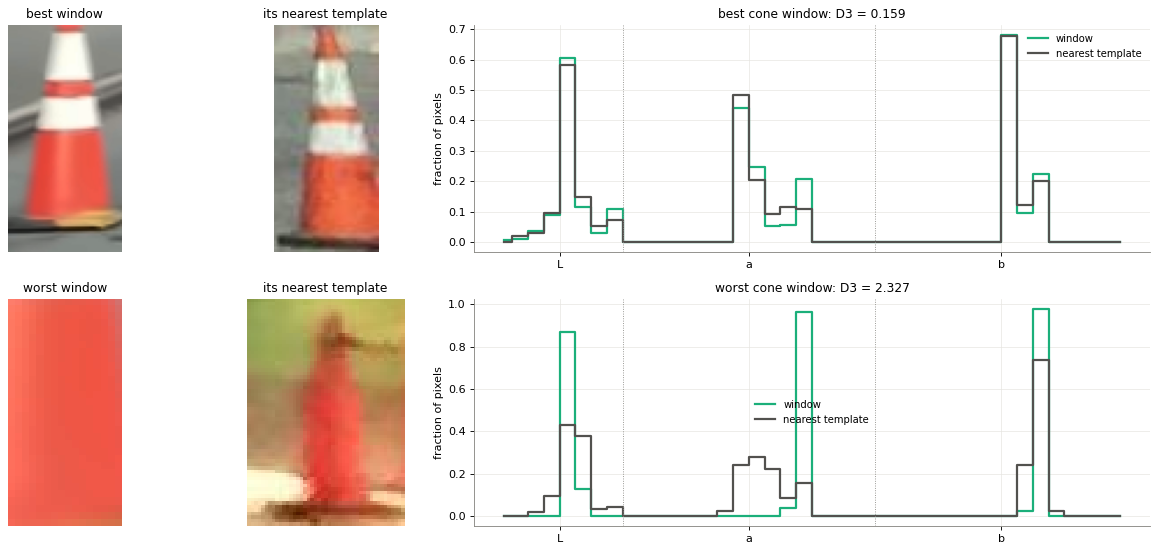

In [7]:
def score(img, conv, cls):
    boxes = multiscale_windows(img.shape, SIZES[cls], STRIDE_FRACTION)
    if cls == "cone":
        boxes = prescreen(orange_mask(img), boxes)
    hists = window_histograms(conv, boxes, SP["bins"], SP["channel_max"])
    return boxes, hists, nearest_template_distance(hists, reference[cls])

scored = {p: {cls: score(images[p], converted[p], cls) for cls in ("cone", "sign")} for p in EXAMPLES}

# Best-matching and worst-matching cone window of the first example, each next to its nearest template
p = EXAMPLES[0]
boxes, hists, dist = scored[p]["cone"]
fig = plt.figure(figsize=(16, 7))
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 3, 0.1])
for row, (name, i) in enumerate([("best", dist.argmin()), ("worst", dist.argmax())]):
    nearest = d3(hists[i][None], reference["cone"])[0].argmin()
    x0, y0, x1, y1 = boxes[i]
    ax = fig.add_subplot(grid[row, 0]); ax.imshow(rgb(images[p][y0:y1, x0:x1])); ax.set_title(f"{name} window"); ax.axis("off")
    crop = cv2.imread(str(TEMPLATE_DIR / load_templates().query("`class` == 'cone'").iloc[nearest]["crop"]))
    ax = fig.add_subplot(grid[row, 1]); ax.imshow(rgb(crop)); ax.set_title("its nearest template"); ax.axis("off")
    plot_hist(fig.add_subplot(grid[row, 2]), {"window": (hists[i], SPACE_COLORS[SPACE]), "nearest template": (reference["cone"][nearest], "#52514e")},
              f"{name} cone window: D3 = {dist[i]:.3f}")
plt.tight_layout()
plt.show()

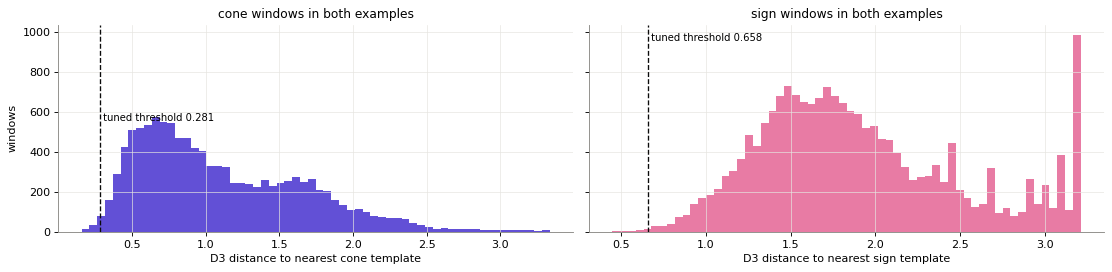

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, cls in zip(axes, ("cone", "sign")):
    ax.hist(np.concatenate([scored[p][cls][2] for p in EXAMPLES]), bins=60, color=CLASS_COLORS[cls])
    ax.axvline(thresholds[cls], color="#0b0b0b", ls="--", lw=1.2)
    ax.text(thresholds[cls], ax.get_ylim()[1] * 0.92, f" tuned threshold {thresholds[cls]:.3f}", fontsize=9)
    ax.set_xlabel(f"D3 distance to nearest {cls} template")
    ax.set_title(f"{cls} windows in both examples")
axes[0].set_ylabel("windows")
plt.tight_layout()
plt.show()

## 5. Detection: NMS + threshold

Many overlapping windows match the same object. NMS keeps the lowest-distance window and drops windows overlapping it
by IoU > 0.3, across all scales. Then only boxes under the class threshold (tuned on the HF validation split and frozen: nothing is tuned on NYC) remain.
There are no annotations, so the boxes are only shown, not scored.

/var/folders/2b/lqbnbrxd07746bw424lpkh8c0000gq/T/ipykernel_56580/2946561013.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


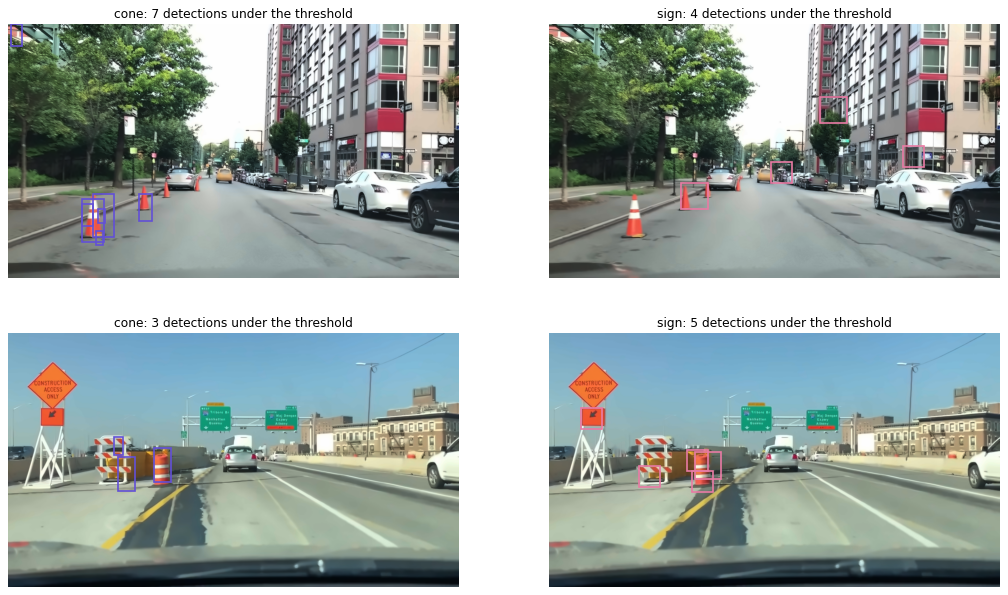

In [9]:
def detections(p):
    rows = []
    for cls, (boxes, hists, dist) in scored[p].items():
        keep = nms(boxes, dist)
        keep = keep[dist[keep] <= thresholds[cls]]
        rows.append(pd.DataFrame({"image_path": p, "cls": cls, "x0": boxes[keep, 0], "y0": boxes[keep, 1],
                                  "x1": boxes[keep, 2], "y1": boxes[keep, 3], "distance": dist[keep]}))
    return pd.concat(rows, ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 9.5), gridspec_kw={"hspace": 0.12})
for row, p in zip(axes, EXAMPLES):
    det = detections(p)
    for ax, cls in zip(row, ("cone", "sign")):
        d = det[det["cls"] == cls]
        ax.imshow(rgb(images[p]))
        draw_boxes(ax, d[["x0", "y0", "x1", "y1"]].to_numpy(), color=CLASS_COLORS[cls], lw=1.5)
        ax.set_title(f"{cls}: {len(d)} detections under the threshold")
        ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Results on all NYC images (qualitative)

There is no ground truth, so no precision or recall. Instead: how many boxes pass the HF-tuned threshold in each color
space, and the lowest-distance detections over all images, to judge by eye.

In [10]:
det = pd.read_parquet(RESULTS / "detections_nyc.parquet")
all_thresholds = pd.DataFrame([(s, c, t) for s, by_cls in json.loads((RESULTS / "thresholds.json").read_text()).items()
                               for c, t in by_cls.items()], columns=["space", "cls", "threshold"])
det = det.merge(all_thresholds).query("distance <= threshold")
counts = det.groupby(["space", "cls"]).agg(detections=("distance", "size"), images=("image_path", "nunique"))
counts["per_image"] = (counts["detections"] / N_IMAGES).round(1)
print(f"Detections under the threshold on {N_IMAGES} NYC images (images = images with at least one)")
display(counts.unstack("cls").loc[["rgb", "hsv", "lab"]])

Detections under the threshold on 300 NYC images (images = images with at least one)


detections        images      per_image      
cls         cone   sign   cone sign      cone  sign
space                                              
rgb         1519   2868    126  159       5.1   9.6
hsv         1189  11203    128  253       4.0  37.3
lab          701   1062    125  154       2.3   3.5

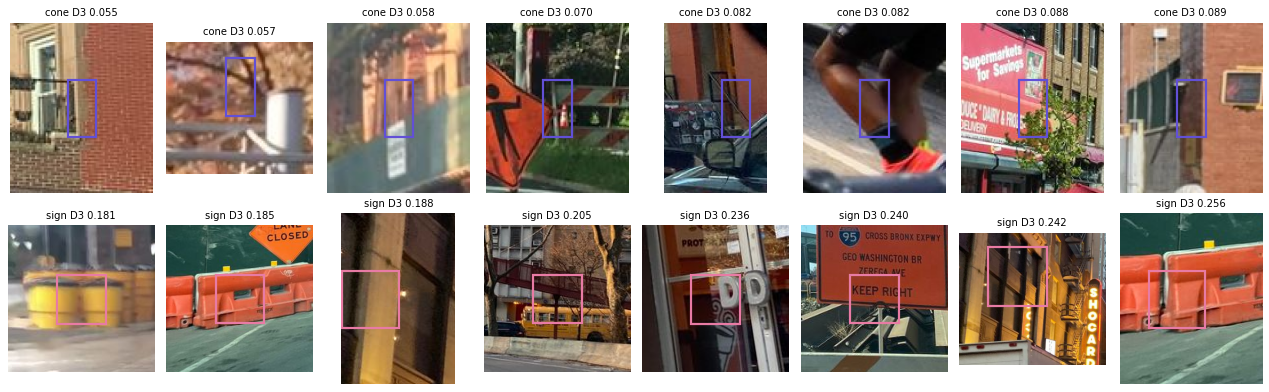

In [11]:
# The 8 lowest-distance detections of each class over all NYC images, with some context around each box
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for row, cls in zip(axes, ("cone", "sign")):
    best = det[(det["space"] == SPACE) & (det["cls"] == cls)].nsmallest(8, "distance")
    for ax, (_, d) in zip(row, best.iterrows()):
        img = cv2.imread(str(IMAGE_DIR / d["image_path"]))
        w, h = d["x1"] - d["x0"], d["y1"] - d["y0"]
        pad = max(w, h)
        cx0, cy0 = max(0, d["x0"] - pad), max(0, d["y0"] - pad)
        ax.imshow(rgb(img[cy0:d["y1"] + pad, cx0:d["x1"] + pad]))
        ax.add_patch(Rectangle((d["x0"] - cx0, d["y0"] - cy0), w, h, fill=False, color=CLASS_COLORS[cls], lw=2))
        ax.set_title(f"{cls} D3 {d['distance']:.3f}", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()